# 29. Сколько весит секунда движения

[Программа курса](../../README_ru.md)

Цветная лента из урока 26 уходит в сторону и возвращается. Все пять пятен узнаваемы на протяжении движения. Незачем писать их цвет заново на каждом шаге. Сначала отделим внешний вид от траектории, затем посмотрим, какой изгиб теряется между редкими опорными кадрами.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "compression_math.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import compression_math as codec
import compression_demos as demos
from reconstruction import scores, benchmark
from splat_render import render_scene, orbit_camera
lang = "ru"

## Семнадцать положений, шестнадцать промежутков

Состояния записаны в моменты от нуля до одной секунды, включая оба края. Между 17 отметками остаётся 16 равных интервалов длиной $1/16=0.0625$ с. В одном состоянии у пяти пятен $5\cdot3=15$ координат. По четыре байта на float32 дают $15\cdot4=60$ байт на состояние. Все центры за секунду займут $17\cdot60=1020$ байт. У двоичного пакета `GSM1` есть ещё 16 байт заголовка: четыре буквы, способ кодирования и резервный байт, три двухбайтовых числа (число кадров, пятен и шаг опор), затем четыре байта цены кода. Итого 1036 байт.

Пакет хранит **только центры** на равномерной сетке. Порядок пятен, их постоянная форма, цвет и непрозрачность приходят из канонической сцены. Длительность тоже нужна для перевода номера кадра в секунды. Исходный JSON урока 26 уже содержит эту сцену, длительность и амплитуды. Мы берём его движение как эталон и исследуем другой способ доставки — таблицу центров для проигрывателя, которому закон движения заранее неизвестен. Для этого конкретного движения исходная формула особенно компактна.

In [2]:
model, xyz = codec.motion_data()
packet = codec.pack_motion(xyz, mode='dense')
print('frames × identities × coordinates:', xyz.shape)
print('header + XYZ:', len(packet), 'bytes')
print('duration:', model['duration'], 's')
print('canonical, including starting centers:', len(codec.pack_static(model['canonical'], 'f32')), 'bytes')

frames × identities × coordinates: (17, 5, 3)
header + XYZ: 1036 bytes
duration: 1.0 s
canonical, including starting centers: 288 bytes


## Опоры и линия между ними

При шаге 8 сохраняются кадры 0, 8 и 16. Три опоры по 60 байт плюс заголовок дают $16+3\cdot60=196$ байт. Чтобы узнать координату в кадре 2 между 0 и 8, сначала найдём долю пути $u=(2-0)/(8-0)=0.25$. Пусть у этой координаты опоры стоят в 0.10 и 0.50 м. Четверть пройденной дороги означает три четверти первого значения и одну четверть второго:

$$
\hat{x}=(1-u)x_0+u x_8=0.75\cdot0.10+0.25\cdot0.50=0.20\text{ м}.
$$

Такой расчёт повторяется для каждой оси каждого пятна. Когда шаг не делит 16 нацело, последний кадр всё равно сохраняется. Например, шаг 6 даёт опоры 0, 6, 12 и 16. В последнем интервале знаменатель равен $16-12=4$, а не 6. Прямой отрезок экономит байты, но сглаживает искривление траектории. Ползунок времени двигает обе копии вместе. У ракурса своё управление. В веб-опыте доступен и JSON собственной сцены из урока 26.

In [3]:
display(demos.codec_lab(29, lang))

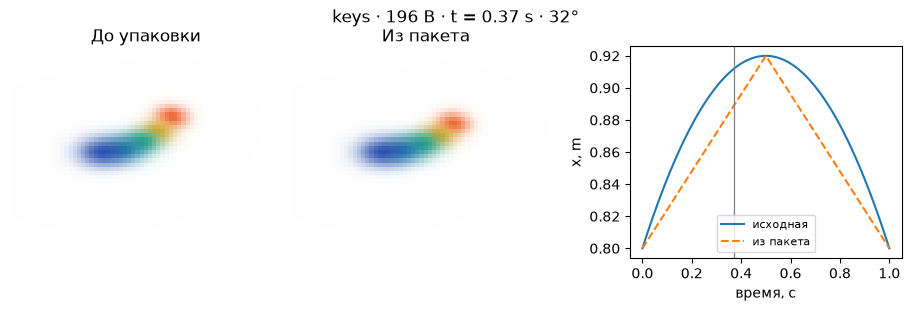

In [4]:
demos.motion_figure(lang, mode='keys', stride=8, time=.37)
plt.show()

## Поправка со знаком

В том же кадре истинное значение могло оказаться 0.236 м. Прогноз равен 0.20 м, значит ошибка прогноза $r=0.236-0.20=0.036$ м. Один шаг кода пусть соответствует $s=0.01$ м. В единицах кода поправка $r/s=3.6$, ближайшее целое — 4. После чтения координата равна $0.20+4\cdot0.01=0.24$ м. Осталось $0.004$ м ошибки. Для значения ниже линии поправка будет отрицательной.

Со знаком в байте помещаются целые от −128 до 127. Здесь диапазон сделан симметричным от −127 до 127. При шаге 0.01 м самая большая записываемая поправка равна $127\cdot0.01=1.27$ м. Без насыщения ошибка округления не больше половины шага. При очень маленьком шаге диапазон сужается, и большой остаток обрежется на границе. Опорные кадры не нуждаются в поправках. Для 14 остальных кадров уйдёт $14\cdot5\cdot3\cdot1=210$ байт. Вместе с опорами $196+210=406$ байт. Каждая поправка отсчитывается от соседних опор, так что ошибка одного промежуточного кадра не перейдёт в следующий.

dense 1036 B; MSE 2.2e-08 clip decode ms 0.0054
keys 196 B; MSE 0.000584908 clip decode ms 0.0846
residual 406 B; MSE 2.8e-08 clip decode ms 0.0983


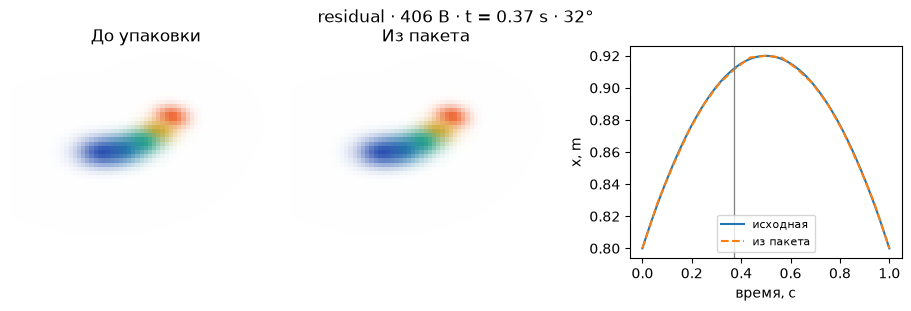

In [5]:
from deformation import scene_at
from compression_math import pose_with_centers
t, angle = .37, 32
cam = orbit_camera(angle, 55)
reference = render_scene(scene_at(model, t), cam, 65, 49)
for mode in ['dense', 'keys', 'residual']:
    data = codec.pack_motion(xyz, mode, stride=8, quantum=.002)
    track = codec.unpack_motion(data)
    pred = pose_with_centers(model['canonical'], codec.sample_track(track, t))
    error = scores(render_scene(pred, cam, 65, 49), reference)['mse']
    print(mode, len(data), 'B; MSE', round(error, 9),
          'clip decode ms', round(benchmark(lambda: codec.unpack_motion(data)), 4))
demos.motion_figure(lang, mode='residual', stride=8, quantum=.002, time=t, angle=angle)
plt.show()

## Момент между кадрами

Время 0.37 с попадает на позицию $0.37\cdot16=5.92$. Проигрыватель смешивает центры декодированных кадров 5 и 6 с долями 0.08 и 0.92. Эталонная модель из урока 26 умеет считать исходную кривую прямо при 0.37 с. Даже файл со всеми 17 кадрами даст небольшую ошибку между ними. Ракурс 32° показывает, как эта разница выглядит для другой камеры. MSE здесь сравнивает с исходным **движением модели**, а не с фотографиями обучающего набора. Скорость в таблице — именно декодирование всего клипа. Быстрые вызовы в браузере замеряются сериями, затем время делится на число вызовов.

**Опыт.** Останется ли выгода от поправок при шаге опор 1? Что произойдёт с размером?

<details>
<summary>Разбор</summary>

Каждый из 17 кадров стал опорным. Промежуточных кадров ноль, значит байтов поправок тоже ноль. Получится тот же размер $16+17\cdot60=1036$ байт, что и у полной записи. Ошибка между моментами измерения по-прежнему зависит от частоты записи.

</details>